# [11.2] CCA, SVCCA, and Representation Alignment

# Introduction

GPT-2 completes “Mary and John … John gave a book to” with “Mary.” We will
reverse the names and try to carry that change between layers. Can common
representation coordinates tell us how to make the model answer “John”?

You will first align a pair of systems whose relationship we know exactly.
Then you will break the argument: independent noise can achieve perfect training
CCA, and a variance cutoff can discard the only feature a task uses. Finally,
we will inspect and intervene on actual language-model layers.

## Content & Learning Objectives

### 1️⃣ Find common coordinates

> - Derive CCA by whitening the two views and taking a cross-covariance SVD.
> - Implement rank-aware whitening and variance-threshold SVCCA.
> - Reuse fitted directions on new examples without changing their signs.

### 2️⃣ Ask what alignment preserves

> - Compare affine-invariant CCA with orthogonal Procrustes.
> - Expose the high-dimensional training-correlation failure mode.
> - Predict target differences through an explicit canonical regression map.

### 3️⃣ Test a real intervention

> - Compare transported changes with actual target-layer donor activations.
> - Inspect complete next-token distributions, controls and failed examples.
> - Explain why representational similarity alone does not establish causal equivalence.

## Setup

This lesson runs on CPU. Its mathematical examples are small; the later model
is a pinned GPT-2 small checkpoint (about 0.5 GB of weights). Work through the implementation cells before
opening their answers. Keep a prediction next to every figure.

The first five exercises take about 100 minutes; allow another hour to investigate
the real-model results. The model study runs on four CPU threads. Its first run
may download the checkpoint; later runs reuse the local cache.


In [1]:
import sys
from pathlib import Path
from types import SimpleNamespace
import torch as t
import numpy as np
import matplotlib.pyplot as plt
from IPython import get_ipython

if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")
root_dir = next(
    p
    for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "chapter11_representation_geometry").exists()
)
if str(root_dir) not in sys.path:
    sys.path.append(str(root_dir))
from chapter11_representation_geometry.exercises.part2_cca_svcca_alignment import (
    alignment_methods_tests as tests,
)

assets_dir = Path("alignment_outputs")
assets_dir.mkdir(exist_ok=True)
t.set_num_threads(4)
plt.style.use("seaborn-v0_8-whitegrid")


# 1️⃣ Find common coordinates

## Whitening gives each retained direction one unit of variance

Let $X\in\mathbb R^{n\times d_x}$ contain one representation per example.
Subtract the **training** mean and write $X_c=U S V^\top$. On the nonzero
singular directions, define

$$W_X=V S^{-1}\sqrt{n-1},\qquad Q_X=X_cW_X.$$

Then $Q_X^\top Q_X/(n-1)=I$. Whitening removes differences in variance scale;
it does not add information. If one feature duplicates another, keep only the
numerical rank. A constant view has no identifiable coordinate to align.

SVCCA adds a variance cutoff before CCA. To retain a fraction $v$ of variation,
keep the smallest $r$ such that $\sum_{i\le r}S_i^2/\sum_jS_j^2\ge v$.
That criterion knows nothing about which feature matters to the model's output.


### Exercise 1 — Whiten a training representation

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend 20 minutes on this exercise.
> ```

Return the training mean `[d]`, retained PCA basis `[d, r]`, whitening map
`[d, r]`, full nonzero variance fractions, and retained/numerical ranks in the
dictionary shown by the solution interface. Use a scale-aware singular-value
threshold `max(x.shape) * eps * largest_singular_value`. Apply the optional rank
cap after the variance cutoff.

<details><summary>Help — a useful starting point</summary>

The right singular vectors are rows of `Vh`. Divide the retained columns by
their singular values, then multiply by `sqrt(n - 1)`. Never divide by a discarded
singular value. The duplicate-direction test checks rank, not a preferred basis sign.

</details>

<details><summary>Expected output</summary>

The whitened training covariance is the identity. A duplicate direction is
removed; a 99% cutoff drops the deliberately tiny third direction.

</details>

<details><summary>Solution</summary>

```python
def svd_whitener(x: t.Tensor, variance_fraction: float = 1.0, max_rank: int | None = None):
    """Training-only centered coordinates with identity covariance on retained rank."""
    if x.ndim != 2 or len(x) < 3 or not x.is_floating_point() or not t.isfinite(x).all():
        raise ValueError(
            "Use a finite floating [examples, features] matrix with at least three rows."
        )
    if not 0 < variance_fraction <= 1 or (max_rank is not None and max_rank < 1):
        raise ValueError("Keep a positive fraction of variance and a positive maximum rank.")
    mean = x.mean(0)
    centered = x - mean
    _, singular, vh = t.linalg.svd(centered, full_matrices=False)
    tolerance = max(x.shape) * t.finfo(x.dtype).eps * singular[0]
    rank = int((singular > tolerance).sum())
    if rank == 0:
        raise ValueError("A constant representation has no identifiable canonical coordinate.")
    fractions = singular[:rank].square() / singular[:rank].square().sum()
    retained = min(
        rank,
        int(
            t.searchsorted(
                fractions.cumsum(0), t.tensor(variance_fraction, device=x.device, dtype=x.dtype)
            ).item()
        )
        + 1,
    )
    if max_rank is not None:
        retained = min(retained, max_rank)
    basis = vh[:retained].T
    whitening = basis * ((len(x) - 1) ** 0.5 / singular[:retained])
    return {
        "mean": mean,
        "basis": basis,
        "whitening": whitening,
        "variance_fractions": fractions,
        "retained_rank": retained,
        "numerical_rank": rank,
    }
```

</details>


In [ ]:
def svd_whitener(x: t.Tensor, variance_fraction: float = 1.0, max_rank: int | None = None):
    raise NotImplementedError("Implement this function before running its tests.")


tests.test_whitening_covariance_rank_and_training_only_fit(SimpleNamespace(**globals()))
tests.test_svcca_variance_cutoff_can_remove_a_low_variance_feature(SimpleNamespace(**globals()))


## CCA: maximize paired correlation after whitening

Whiten both views using the same **paired example rows**. Their cross-covariance
is $C=Q_X^\top Q_Y/(n-1)$. Take $C=L\,\mathrm{diag}(\rho)\,R^\top$.
The canonical maps are $A=W_XL$ and $B=W_YR$.

The training canonical coordinates $Z_X=X_cA$ and $Z_Y=Y_cB$ each have identity
covariance, and their cross-covariance is diagonal with entries $\rho_i$.
These are the canonical correlations. Each direction pair has a joint sign
ambiguity; tied correlations also allow rotations within a tied subspace.

The maps are learned from paired training rows. On new rows, apply those same
maps and compute **signed** correlations. Refitting directions or taking absolute
values on the test set could hide a failed transfer.


### Exercise 2 — Fit and evaluate canonical coordinates

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend 30 minutes on this exercise.
> ```

Implement CCA and its held-out evaluation. Use your whitening function for
both views. `variance_fraction=1` uses all numerical-rank directions; a smaller
fraction gives the SVCCA preprocessing step. `max_rank` is an optional training-only
cap. Return maps `[d_x, k]` and `[d_y, k]`, correlations `[k]`, and target loadings
`Z_y.T @ Y_centered / (n - 1)` with shape `[k, d_y]` for the later transport.
Constant evaluation columns should return NaN, not a misleading success score.

<details><summary>Help — a useful starting point</summary>

After whitening, ordinary SVD solves the optimization. Multiply the whitening
maps by the left/right singular vectors. Evaluation subtracts the fitted training
means; its Pearson statistic can center the resulting coordinates over the
measurement sample without refitting a new direction.

</details>

<details><summary>Expected output</summary>

The known correlations are exactly 0.95, 0.60 and 0.10, even after invertible
mixing and translations. Reversing the held-out target reverses their signs.
Independent wide training views can still score 1.0—keep reading before treating
that last result as a successful alignment.

</details>

<details><summary>Solution</summary>

```python
def fit_cca(
    x: t.Tensor,
    y: t.Tensor,
    components: int | None = None,
    variance_fraction: float = 1.0,
    max_rank: int | None = None,
):
    """Whiten each training view, then align by SVD of the cross-covariance."""
    if len(x) != len(y) or x.dtype != y.dtype or x.device != y.device:
        raise ValueError("CCA needs paired rows with matching dtype and device.")
    left = svd_whitener(x, variance_fraction, max_rank)
    right = svd_whitener(y, variance_fraction, max_rank)
    qx = (x - left["mean"]) @ left["whitening"]
    qy = (y - right["mean"]) @ right["whitening"]
    u, correlations, vh = t.linalg.svd(qx.T @ qy / (len(x) - 1), full_matrices=False)
    available = len(correlations)
    count = available if components is None else components
    if not 1 <= count <= available:
        raise ValueError("Canonical component count must fit both retained ranks.")
    x_map = left["whitening"] @ u[:, :count]
    y_map = right["whitening"] @ vh[:count].T
    canonical_y = (y - right["mean"]) @ y_map
    # Unit-variance canonical targets have this least-squares loading back to Y.
    y_loading = canonical_y.T @ (y - right["mean"]) / (len(x) - 1)
    return {
        "left": left,
        "right": right,
        "x_map": x_map,
        "y_map": y_map,
        "correlations": correlations[:count],
        "y_loading": y_loading,
        "train_rows": len(x),
    }


def paired_column_correlations(x: t.Tensor, y: t.Tensor):
    """Signed Pearson correlations; constant columns are explicitly undefined."""
    if x.ndim != 2 or x.shape != y.shape or len(x) < 3:
        raise ValueError("Use equally sized paired coordinate matrices.")
    xc = x - x.mean(0)
    yc = y - y.mean(0)
    denominator = xc.square().sum(0).sqrt() * yc.square().sum(0).sqrt()
    return t.where(denominator > 0, (xc * yc).sum(0) / denominator, t.full_like(denominator, t.nan))


def heldout_correlations(x: t.Tensor, y: t.Tensor, fit: dict):
    """Reuse both fitted transformations; never find new test-set directions."""
    return paired_column_correlations(
        (x - fit["left"]["mean"]) @ fit["x_map"], (y - fit["right"]["mean"]) @ fit["y_map"]
    )
```

</details>


In [ ]:
def fit_cca(
    x: t.Tensor,
    y: t.Tensor,
    components: int | None = None,
    variance_fraction: float = 1.0,
    max_rank: int | None = None,
):
    raise NotImplementedError("Implement this function before running its tests.")


def paired_column_correlations(x: t.Tensor, y: t.Tensor):
    raise NotImplementedError("Implement this function before running its tests.")


def heldout_correlations(x: t.Tensor, y: t.Tensor, fit: dict):
    raise NotImplementedError("Implement this function before running its tests.")


tests.test_canonical_correlations_match_known_oracle_under_affine_maps(SimpleNamespace(**globals()))
tests.test_heldout_direction_is_fixed_and_negative_correlation_is_visible(
    SimpleNamespace(**globals())
)
tests.test_independent_high_width_views_overfit_training_and_fail_heldout(
    SimpleNamespace(**globals())
)


## A visible counterexample: identical score, different evidence

The two synthetic systems below share three latent variables through noisy,
invertibly mixed observations. Their training correlations are known. The
row-permutation control preserves each view's marginal distribution but destroys
the pairing. New examples are generated independently from the same mechanism.
Predict which spectrum should transfer to them.


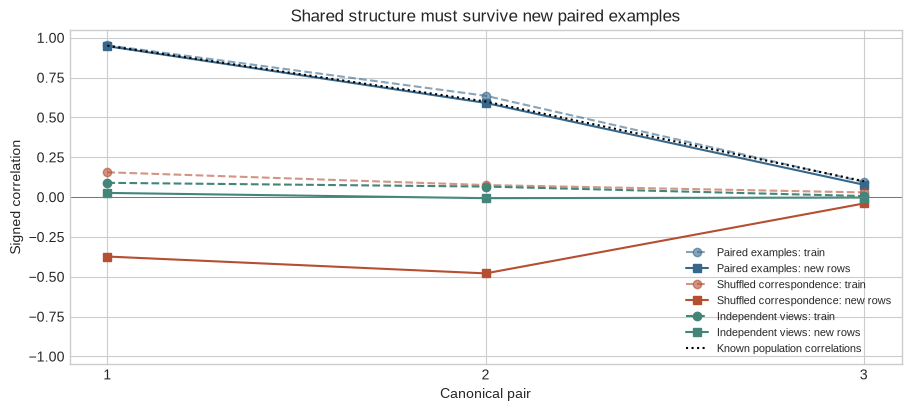

In [4]:
generator = t.Generator().manual_seed(811)
rho = t.tensor([0.95, 0.60, 0.10], dtype=t.float64)
a = t.tensor([[2.0, 1.0, 0.0], [0.0, 3.0, 1.0], [1.0, 0.0, 2.0]], dtype=t.float64)
b = t.tensor([[1.0, 0.0, 2.0], [1.0, 2.0, 0.0], [0.0, 1.0, 3.0]], dtype=t.float64)


def paired_sample(rows):
    shared = t.randn(rows, 3, generator=generator, dtype=t.float64)
    noise = t.randn(rows, 3, generator=generator, dtype=t.float64)
    return shared @ a + 7, (shared * rho + noise * t.sqrt(1 - rho.square())) @ b - 13


train_x, train_y = paired_sample(500)
new_x, new_y = paired_sample(1000)
paired_fit = fit_cca(train_x, train_y)
permutation = t.randperm(len(train_y), generator=generator)
shuffled_fit = fit_cca(train_x, train_y[permutation])
independent_train_y = t.randn(len(train_x), 3, generator=generator, dtype=t.float64) @ b - 13
independent_new_y = t.randn(len(new_x), 3, generator=generator, dtype=t.float64) @ b - 13
independent_fit = fit_cca(train_x, independent_train_y)
fig, ax = plt.subplots(figsize=(9, 4), constrained_layout=True)
for fit, label, color in [
    (paired_fit, "Paired examples", "#37688c"),
    (shuffled_fit, "Shuffled correspondence", "#b64e32"),
]:
    ax.plot(
        range(1, 4), fit["correlations"], "o--", color=color, alpha=0.6, label=label + ": train"
    )
    ax.plot(
        range(1, 4),
        heldout_correlations(new_x, new_y, fit),
        "s-",
        color=color,
        label=label + ": new rows",
    )
ax.plot(
    range(1, 4),
    independent_fit["correlations"],
    "o--",
    color="#438579",
    label="Independent views: train",
)
ax.plot(
    range(1, 4),
    heldout_correlations(new_x, independent_new_y, independent_fit),
    "s-",
    color="#438579",
    label="Independent views: new rows",
)
ax.plot(range(1, 4), rho, "k:", label="Known population correlations")
ax.axhline(0, color="#777", linewidth=0.7)
ax.set(
    xlabel="Canonical pair",
    ylabel="Signed correlation",
    xticks=[1, 2, 3],
    ylim=(-1.05, 1.05),
    title="Shared structure must survive new paired examples",
)
ax.legend(fontsize=8)
fig.savefig(assets_dir / "alignment_known_correlations.png", dpi=160)
plt.show()


<details><summary>Interpreting the signed control</summary>

A shuffled training correspondence can produce negative correlations on new,
correctly paired data. The real views still contain shared information, but
the shuffled fit aligns arbitrary mixtures and signs. We display the whole
range from −1 to 1. The separate independent-view control removes the shared
latent source itself and stays near zero. These are different failures, not
interchangeable labels for a single null.

</details>


# 2️⃣ Ask what alignment preserves

## Try It Yourself — make independent noise look perfectly aligned

Change `training_examples` or the feature widths. When both centered views
span the full `(n - 1)`-dimensional example space, their canonical training
correlations are all one, even though the views were generated independently.
We have fitted the sample's row space, not discovered a shared latent feature.
The new-row curves expose the difference. All five seeds remain in the plot.

<details><summary>Help — why can the first three correlations reach one before the vertical line?</summary>

Two centered sample subspaces of ranks $r_x,r_y$ in an $(n-1)$-dimensional
space intersect in at least $r_x+r_y-(n-1)$ dimensions. A shared sample-space
direction gives canonical correlation one, even when the features were generated
independently. At width 16 here, the two ranks are 16 and 19, so at least twelve
training canonical correlations are already one. The figure averages only the
first three. The vertical line marks when each view can span the whole centered
sample space, a stronger condition than needing three intersecting directions.

</details>


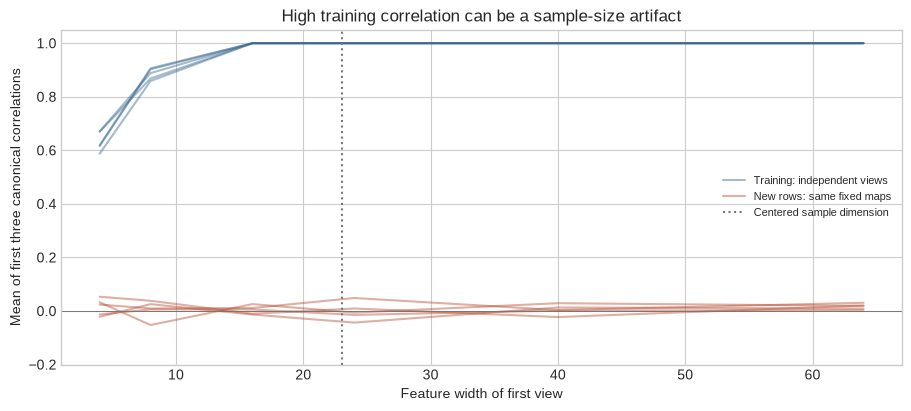

In [5]:
training_examples = 24
widths = [4, 8, 16, 24, 40, 64]
noise_results = []
for seed in range(5):
    gen = t.Generator().manual_seed(820 + seed)
    for width in widths:
        x = t.randn(training_examples, width, generator=gen, dtype=t.float64)
        y = t.randn(training_examples, width + 3, generator=gen, dtype=t.float64)
        fitted = fit_cca(x, y, components=min(3, width, training_examples - 1))
        new_x = t.randn(500, width, generator=gen, dtype=t.float64)
        new_y = t.randn(500, width + 3, generator=gen, dtype=t.float64)
        noise_results.append(
            {
                "seed": seed,
                "width": width,
                "train": float(fitted["correlations"].mean()),
                "new": float(heldout_correlations(new_x, new_y, fitted).mean()),
            }
        )
fig, ax = plt.subplots(figsize=(9, 4), constrained_layout=True)
for seed in range(5):
    rows = [row for row in noise_results if row["seed"] == seed]
    ax.plot(
        widths,
        [row["train"] for row in rows],
        color="#37688c",
        alpha=0.45,
        label="Training: independent views" if seed == 0 else None,
    )
    ax.plot(
        widths,
        [row["new"] for row in rows],
        color="#b64e32",
        alpha=0.45,
        label="New rows: same fixed maps" if seed == 0 else None,
    )
ax.axvline(training_examples - 1, color="#777", linestyle=":", label="Centered sample dimension")
ax.axhline(0, color="#777", linewidth=0.7)
ax.set(
    xlabel="Feature width of first view",
    ylabel="Mean of first three canonical correlations",
    ylim=(-0.2, 1.05),
    title="High training correlation can be a sample-size artifact",
)
ax.legend(fontsize=8)
fig.savefig(assets_dir / "alignment_noise_overfit.png", dpi=160)
plt.show()


### Exercise 3 — Fit an orthogonal alignment

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend 15 minutes on this exercise.
> ```

Fit an orthogonal row-vector transform $Q$ minimizing

$$\lVert X_{\mathrm{centered}}Q-Y_{\mathrm{centered}}\rVert_F^2.$$

Return both training means and `Q`. The feature widths must match.
Reflections are allowed; axis-dependent scaling is not. A later PCA preprocessing
step can give two different-width layers equal retained widths.

<details><summary>Help — a useful starting point</summary>

Take the SVD of `X_centered.T @ Y_centered`. The optimizer is `U @ Vh`.
A common bug is to multiply by singular values: that would change the length-preserving
constraint into another model.

</details>

<details><summary>Expected output</summary>

A rotated, reflected and translated copy is reconstructed. A stretched axis
remains a visible error, although CCA can give that same pair perfect correlations.

</details>

<details><summary>Solution</summary>

```python
def fit_procrustes(x: t.Tensor, y: t.Tensor):
    """Minimize paired training squared error using translation and an orthogonal map."""
    if x.ndim != 2 or x.shape != y.shape or len(x) < 3:
        raise ValueError("Procrustes needs paired matrices of equal feature width.")
    mean_x = x.mean(0)
    mean_y = y.mean(0)
    u, _, vh = t.linalg.svd((x - mean_x).T @ (y - mean_y), full_matrices=False)
    return {"mean_x": mean_x, "mean_y": mean_y, "rotation": u @ vh}
```

</details>


In [ ]:
def fit_procrustes(x: t.Tensor, y: t.Tensor):
    raise NotImplementedError("Implement this function before running its tests.")


tests.test_procrustes_preserves_lengths_and_cannot_undo_anisotropic_scaling(
    SimpleNamespace(**globals())
)


## Specify a transport rule before calling an alignment causal

CCA gives coordinates, not a unique intervention. We will use a particular
linear prediction rule. With unit-covariance target canonical coordinates,
fit target loadings $D_Y=Z_Y^\top Y_c/(n-1)$. The fitted cross-covariance predicts
$Z_Y$ from $Z_X$ through $\mathrm{diag}(\rho)$. Transport a source difference as

$$\Delta y=(\Delta x A_k)\,\mathrm{diag}(\rho_{1:k})\,D_{Y,1:k}.$$

This is canonical regression with a chosen truncation rank. We can test it on
new paired examples, then ask whether replacing a target activation using that
predicted difference reproduces a real donor intervention. The latter is an
additional empirical test, not a property of a large canonical correlation.


### Exercise 4 — Transport a difference and fit a baseline

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend 25 minutes on this exercise.
> ```

Implement the canonical difference map above, allowing rank zero as an exact
no-op. Also implement ridge prediction as a baseline. Keep its intercept
unpenalized; the dual solve avoids a large `[features, features]` matrix when
training examples are scarce. Both fits use training rows only.

<details><summary>Help — a useful starting point</summary>

A difference has no intercept. Apply only the fitted linear maps, and use the
first `k` rows of the target loading. For ridge, solve `(Xc @ Xc.T + λI) @ Z = Yc`,
then return `Xc.T @ Z`. At zero ridge use a rank-aware least-squares solver.

</details>

<details><summary>Expected output</summary>

On an exact linear pair, transported changes equal the known target changes.
A target coordinate fixed at 19 does not move. The ridge baseline matches an
independent primal normal-equation oracle.

</details>

<details><summary>Solution</summary>

```python
def cca_difference_transport(delta_x: t.Tensor, fit: dict, components: int | None = None):
    """Predict a target difference through a truncated canonical regression map.

    This is a specified linear transport rule, not a causal conclusion from CCA.
    """
    count = len(fit["correlations"]) if components is None else components
    if not 0 <= count <= len(fit["correlations"]):
        raise ValueError("Transport rank must fit the learned coordinates.")
    return ((delta_x @ fit["x_map"][:, :count]) * fit["correlations"][:count]) @ fit["y_loading"][
        :count
    ]


def fit_ridge_transport(x: t.Tensor, y: t.Tensor, ridge: float = 1e-3):
    """Training-only linear prediction baseline, with an unpenalized intercept."""
    if len(x) != len(y) or ridge < 0:
        raise ValueError("Use paired training rows and a nonnegative ridge.")
    mx = x.mean(0)
    my = y.mean(0)
    xc = x - mx
    yc = y - my
    if ridge == 0:
        weights = t.linalg.lstsq(
            xc, yc, driver="gelsd" if x.device.type == "cpu" else "gels"
        ).solution
    else:
        # Dual form avoids a feature-by-feature matrix when examples are scarce.
        weights = xc.T @ t.linalg.solve(
            xc @ xc.T + ridge * t.eye(len(x), device=x.device, dtype=x.dtype), yc
        )
    return {"mean_x": mx, "mean_y": my, "weights": weights}
```

</details>


In [ ]:
def cca_difference_transport(delta_x: t.Tensor, fit: dict, components: int | None = None):
    raise NotImplementedError("Implement this function before running its tests.")


def fit_ridge_transport(x: t.Tensor, y: t.Tensor, ridge: float = 1e-3):
    raise NotImplementedError("Implement this function before running its tests.")


tests.test_canonical_transport_equals_exact_linear_map_and_zero_rank_noop(
    SimpleNamespace(**globals())
)
tests.test_ridge_transport_matches_primal_oracle_and_unpenalized_intercept(
    SimpleNamespace(**globals())
)


### Exercise 5 — Compare complete output distributions

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> You should spend 10 minutes on this exercise.
> ```

Return per-example `KL(target || actual)` from aligned `[examples, vocabulary]`
logits. The target will be a measured native donor intervention. Use every
vocabulary token and compute log probabilities stably.

<details><summary>Help — a useful starting point</summary>

Use `log_softmax`. Weight `log_p - log_q` by `exp(log_p)`, then sum across
vocabulary. KL is directional; swapping arguments changes the question.

</details>

<details><summary>Expected output</summary>

The explicit categorical-distribution oracle matches exactly. Identical
logits give zero, and reversing the KL arguments gives a different result.

</details>

<details><summary>Solution</summary>

```python
def distribution_kl(target_logits: t.Tensor, actual_logits: t.Tensor):
    """Per-example KL(target || actual), using all vocabulary tokens."""
    if target_logits.shape != actual_logits.shape or target_logits.ndim != 2:
        raise ValueError("Use aligned [examples, vocabulary] logits.")
    logp = target_logits.log_softmax(-1)
    logq = actual_logits.log_softmax(-1)
    return (logp.exp() * (logp - logq)).sum(-1)
```

</details>


In [ ]:
def distribution_kl(target_logits: t.Tensor, actual_logits: t.Tensor):
    raise NotImplementedError("Implement this function before running its tests.")


tests.test_distribution_kl_uses_full_vocabulary_and_correct_orientation(
    SimpleNamespace(**globals())
)


## Try It Yourself — preserve almost all variance and lose the task

The third latent coordinate is tiny but controls the output below. Change its
scale or the retained variance fraction. We fit alignment using paired training
states, change that source coordinate and read the target system's output.
The full-rank map should transfer the task change; a variance cutoff can remove
it completely. The unedited target and zero-rank map are explicit controls.


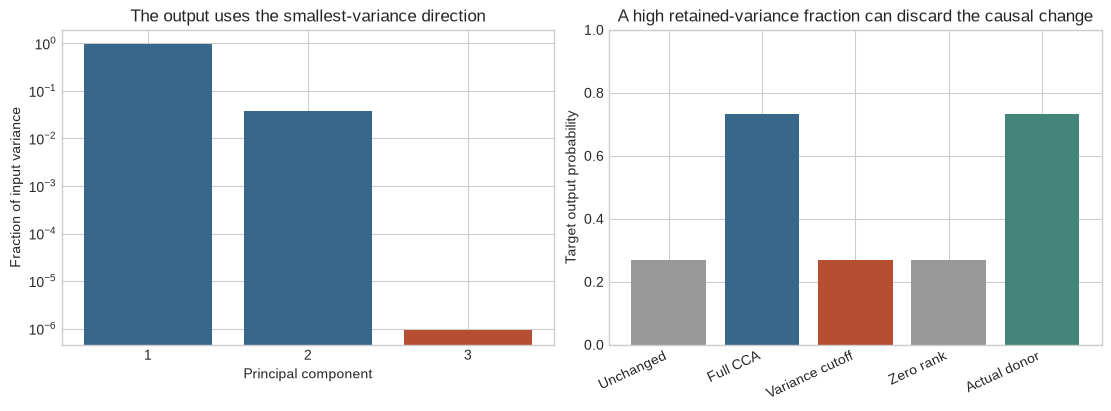

In [9]:
causal_scale = 0.01
retained_variance = 0.99
gen = t.Generator().manual_seed(831)
latent = t.randn(200, 3, generator=gen, dtype=t.float64)
scales = t.tensor([10.0, 2.0, causal_scale], dtype=t.float64)
source = latent * scales
rotation = t.linalg.qr(t.randn(3, 3, generator=gen, dtype=t.float64)).Q
target = source @ rotation
full_fit = fit_cca(source, target)
truncated_fit = fit_cca(source, target, variance_fraction=retained_variance)
receiver = t.tensor([[0.2, -0.3, -1.0]], dtype=t.float64) * scales
donor = receiver.clone()
donor[:, 2] = causal_scale
original_target = receiver @ rotation
true_donor_target = donor @ rotation
changes = {
    "Unchanged": t.zeros_like(original_target),
    "Full CCA": cca_difference_transport(donor - receiver, full_fit),
    "Variance cutoff": cca_difference_transport(donor - receiver, truncated_fit),
    "Zero rank": cca_difference_transport(donor - receiver, full_fit, 0),
    "Actual donor": true_donor_target - original_target,
}


def target_output(state):
    return ((state @ rotation.T)[:, 2] / causal_scale).sigmoid()


values = [float(target_output(original_target + change)[0]) for change in changes.values()]
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
axes[0].bar(
    range(1, 4), full_fit["left"]["variance_fractions"], color=["#37688c", "#37688c", "#b64e32"]
)
axes[0].set(
    xlabel="Principal component",
    ylabel="Fraction of input variance",
    yscale="log",
    xticks=[1, 2, 3],
    title="The output uses the smallest-variance direction",
)
axes[1].bar(range(len(values)), values, color=["#999", "#37688c", "#b64e32", "#999", "#438579"])
axes[1].set_xticks(range(len(values)), changes.keys(), rotation=25, ha="right")
axes[1].set(
    ylabel="Target output probability",
    ylim=(0, 1),
    title="A high retained-variance fraction can discard the causal change",
)
fig.savefig(assets_dir / "alignment_variance_causal_failure.png", dpi=160)
plt.show()


# 3️⃣ Test a real intervention

## Who receives the book?

Consider these paired prompts:

> When Mary and John went to the store, John gave a book to **Mary**.
>
> When John and Mary went to the store, Mary gave a book to **John**.

The names occur in both prompts; their roles differ. This is a small version of
the indirect-object task in the original ARENA transformer chapter and
[Wang et al.](https://arxiv.org/abs/2211.00593). We will use its paired prompts,
without assuming that GPT-2 answers every one correctly or reproducing its full
circuit analysis.

Let $x$ be a residual activation at the **last prompt position** of a source
layer, and $y$ the activation at the same position of a later layer. Fit an
alignment on paired $x,y$ from ordinary training prompts. For a new recipient
prompt $r$ and its role-reversed donor $d$, compare:

$$y'_r=y_r+(x_d-x_r)M \quad\text{with}\quad y'_r=y_d.$$

Both replacements run inside the recipient prompt. The first transports a
source difference through our learned map. The second inserts the actual target
activation. Earlier positions keep their recipient activations. Therefore, even
the native target donor need not reproduce the donor prompt's full output.

**Predict before running:** if training CCA is near one, must these two edits
produce the same token? What would an unchanged-answer control tell you when
the native donor itself barely changes the output?

<details><summary>Help — compare the right counterfactual</summary>

The target distribution is measured by actually replacing the target activation
and resuming the model. It is not a one-hot vector containing the desired name.
Low KL means we reproduced this local intervention. It does not mean the
intervention solved IOI. We show next-token name accuracy separately.

</details>

## Fit on training prompts; choose ranks on development prompts

There are 72 training prompts, 48 development prompts and 96 final prompts.
Templates are disjoint. Training/development use twelve names; final uses sixteen.
The final set contains 66 rows with training names and 30 including new names.
The two orientations of each name pair stay in the same split. These templated,
related examples are not 96 independent natural-language tasks.

We compare residual inputs at layers 2→6, 4→8 and 6→10 (zero indexed). CCA first
retains at most 32 training PCs in each view to limit the sample-dimension problem.
SVCCA retains 99% of training variance. Each then transports 2, 4, 8 or 16 canonical
coordinates, limited by available rank. Procrustes uses equal-rank training PCA
coordinates; ridge uses a fixed 0.1 penalty. All methods use the same prompt pairs.

A separate development run selected rank 16 for each aligned method by smallest
KL to the measured donor. We keep those choices and display every rank on final
prompts. The random controls match each selected CCA edit's norm, with 16 draws.
A shuffled CCA fit retains real activation distributions but breaks training
correspondence. It may learn incidental common structure; it is not independent
noise.


In [10]:
import gzip, json, os
from transformers import AutoModelForCausalLM, AutoTokenizer
from chapter11_representation_geometry.exercises.part2_cca_svcca_alignment.alignment_ioi_data import (
    paired_rows,
    donor_indices,
)

section_dir = root_dir / "chapter11_representation_geometry/exercises/part2_cca_svcca_alignment"
protocol = json.loads((section_dir / "alignment_protocol.json").read_text())
for split in ["train", "development", "final"]:
    examples = paired_rows(split)
    print(f"{split}: {len(examples)} prompts; first example: {examples[0]['prompt']}")
model = (
    AutoModelForCausalLM.from_pretrained(
        protocol["model_id"],
        revision=protocol["revision"],
        dtype=t.float32,
        attn_implementation="eager",
    )
    .cpu()
    .eval()
)
tokenizer = AutoTokenizer.from_pretrained(protocol["model_id"], revision=protocol["revision"])
tokenizer.padding_side = "left"
tokenizer.pad_token = tokenizer.eos_token


train: 72 prompts; first example: When Mary and John went to the store, John gave a book to
development: 48 prompts; first example: While Mary and John were at the school, John gave a pen to
final: 96 prompts; first example: After Mary and John went to the cafe, John gave a cup to


W0906 14:48:53.477000 987446 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


W0906 14:48:53.487000 987446 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

## Provided code: capture one position and put a replacement back

These hooks expose native residual inputs. The supplied tokenizer code finds the
source-name span and creates position IDs from the attention mask, so left
padding does not shift the prompt's positions. In this study we select the final
prediction position. Each hook is removed in a `finally` block, including if a
forward pass fails. Read the assignment in `replace_rows`: it changes only the
chosen position, then the model continues normally.

The two helpers return actual activations/logits. No CCA, whitening or fitted
alignment is hidden here. A no-op test below replaces captured activations with
themselves and requires identical logits.


In [11]:
def encode_rows(tokenizer, rows):
    batch = tokenizer(
        [r["prompt"] for r in rows], return_tensors="pt", padding=True, return_offsets_mapping=True
    )
    offsets = batch.pop("offset_mapping")
    spans = t.tensor([r["span"] for r in rows])
    mask = batch["attention_mask"].bool()
    matches = (offsets[:, :, 0] < spans[:, None, 1]) & (offsets[:, :, 1] > spans[:, None, 0]) & mask
    if not matches.sum(1).eq(1).all():
        raise ValueError("Every source word must align to exactly one real token.")
    positions = matches.long().argmax(1)
    selected = offsets[t.arange(len(rows)), positions]
    if not (selected[:, 0].le(spans[:, 0]) & selected[:, 1].eq(spans[:, 1])).all():
        raise ValueError("Token offsets must cover the entire source word.")
    if not mask[:, -1].all():
        raise ValueError("Use left padding before reading last-token logits.")
    batch["position_ids"] = (batch["attention_mask"].long().cumsum(1) - 1).clamp_min(0)
    return dict(batch), positions


@t.inference_mode()
def capture_rows(model, tokenizer, rows, batch_size=24, position_mode="word"):
    boundaries = (
        [*model.transformer.h, model.transformer.ln_f]
        if model.config.model_type == "gpt2"
        else [*model.gpt_neox.layers, model.gpt_neox.final_layer_norm]
    )
    hidden = []
    logits = []
    for start in range(0, len(rows), batch_size):
        batch, positions = encode_rows(tokenizer, rows[start : start + batch_size])
        cache = {}
        handles = []
        if position_mode == "prediction":
            positions = t.full_like(positions, batch["input_ids"].shape[1] - 1)
        elif position_mode != "word":
            raise ValueError("Choose word or prediction position.")

        def make_hook(index):
            def hook(module, args):
                cache[index] = args[0][t.arange(len(positions)), positions].detach().clone()

            return hook

        try:
            for index, block in enumerate(boundaries):
                handles.append(block.register_forward_pre_hook(make_hook(index)))
            output = model(**batch, use_cache=False).logits[:, -1].float()
        finally:
            for handle in handles:
                handle.remove()
        if len(cache) != len(boundaries):
            raise ValueError("Not every native residual boundary was captured.")
        hidden.append(t.stack([cache[i] for i in range(len(boundaries))], 1))
        logits.append(output)
    return {"activations": t.cat(hidden), "logits": t.cat(logits)}


@t.inference_mode()
def replace_rows(model, tokenizer, rows, layer, replacements, batch_size=24, position_mode="word"):
    boundaries = (
        [*model.transformer.h, model.transformer.ln_f]
        if model.config.model_type == "gpt2"
        else [*model.gpt_neox.layers, model.gpt_neox.final_layer_norm]
    )
    block = boundaries[layer]
    logits = []
    for start in range(0, len(rows), batch_size):
        batch, positions = encode_rows(tokenizer, rows[start : start + batch_size])
        replacement = replacements[start : start + batch_size]
        if position_mode == "prediction":
            positions = t.full_like(positions, batch["input_ids"].shape[1] - 1)
        elif position_mode != "word":
            raise ValueError("Choose word or prediction position.")

        def hook(module, args):
            changed = args[0].clone()
            changed[t.arange(len(positions)), positions] = replacement.to(changed)
            return (changed, *args[1:])

        handle = block.register_forward_pre_hook(hook)
        try:
            output = model(**batch, use_cache=False).logits[:, -1].float()
        finally:
            handle.remove()
        logits.append(output)
    return t.cat(logits)


## Build the candidate maps from your functions

`cca_difference_transport` is linear in a source difference. Applying it to the
identity matrix exposes its full matrix, which lets us reuse it across batches.
The Procrustes comparator is rigid only inside its retained PCA coordinates;
the overall rank-limited map is not an isometry of the full residual stream.
Translations cancel when transporting a difference.

Follow one candidate through the code before continuing. Its PCA directions,
canonical directions and output loading are all fitted on training rows.


In [12]:
def fit_candidates(x, y):
    """Each candidate's parameters are learned from the paired training rows."""
    candidates = []
    cca = fit_cca(x, y, max_rank=32)
    svcca = fit_cca(x, y, variance_fraction=0.99)
    shuffled = fit_cca(
        x, y[t.randperm(len(y), generator=t.Generator().manual_seed(910))], max_rank=32
    )
    for requested in [2, 4, 8, 16]:
        for method, fit in [("cca", cca), ("svcca", svcca), ("shuffled_cca", shuffled)]:
            k = min(requested, len(fit["correlations"]))
            mapping = cca_difference_transport(
                t.eye(x.shape[1], device=x.device, dtype=x.dtype), fit, k
            )
            candidates.append(
                {
                    "name": f"{method}_rank{requested}",
                    "method": method,
                    "requested_rank": requested,
                    "effective_rank": k,
                    "map": mapping,
                    "fit": fit,
                }
            )
        px = svd_whitener(x, max_rank=requested)
        py = svd_whitener(y, max_rank=requested)
        k = min(px["retained_rank"], py["retained_rank"])
        bx = px["basis"][:, :k]
        by = py["basis"][:, :k]
        rigid = fit_procrustes((x - px["mean"]) @ bx, (y - py["mean"]) @ by)
        candidates.append(
            {
                "name": f"procrustes_rank{requested}",
                "method": "procrustes",
                "requested_rank": requested,
                "effective_rank": k,
                "map": bx @ rigid["rotation"] @ by.T,
            }
        )
    ridge = fit_ridge_transport(x, y, 0.1)
    candidates.append(
        {
            "name": "ridge_0.1",
            "method": "ridge",
            "requested_rank": None,
            "effective_rank": int(t.linalg.matrix_rank(ridge["weights"])),
            "map": ridge["weights"],
        }
    )
    return candidates


## Run the actual donor and transported interventions

The provided experiment loop below calls your maps and your full-vocabulary KL.
It first fits training activations and reruns the development comparisons. Only
then does it capture final activations and test every frozen candidate. All
examples remain, including native-donor failures and wrong transported answers.
The files are optional records of the same calculations displayed below.

Expected output: each of the three layer pairs announces development completion,
then completion of all final candidates and random controls. A failed no-op
raises an error before any corresponding result is accepted. The finished run
contains 12,816 recorded outcomes and 12,888 model-forward rows.


In [13]:
def answer_record(
    rows, logits, donor_logits, tokenizer, condition, source_layer, target_layer, draw=None
):
    kl = distribution_kl(donor_logits, logits)
    top = logits.argmax(-1)
    donor_top = donor_logits.argmax(-1)
    output = []
    for i, row in enumerate(rows):
        expected = tokenizer.encode(" " + row["recipient"], add_special_tokens=False)
        changed = tokenizer.encode(" " + row["subject"], add_special_tokens=False)
        if len(expected) != 1 or len(changed) != 1:
            raise ValueError("Names must be single output tokens.")
        output.append(
            {
                "row_id": row["id"],
                "split": row["split"],
                "condition": condition,
                "source_layer": source_layer,
                "target_layer": target_layer,
                "draw": draw,
                "seen_names": row["word_seen_in_training"],
                "kl_to_native_donor": float(kl[i]),
                "top_token_id": int(top[i]),
                "top_token_text": tokenizer.decode(int(top[i])),
                "native_donor_top_token_id": int(donor_top[i]),
                "native_top_agreement": bool(top[i] == donor_top[i]),
                "original_recipient_top": bool(top[i] == expected[0]),
                "changed_recipient_top": bool(top[i] == changed[0]),
                "recipient_logit": float(logits[i, expected[0]]),
                "subject_logit": float(logits[i, changed[0]]),
            }
        )
    return output


def run_alignment_study(model, tokenizer, protocol, output_directory):
    output = Path(output_directory)
    output.mkdir(parents=True, exist_ok=False)
    (output / "protocol.json").write_text(json.dumps(protocol, indent=2) + "\n")
    tokenizer.padding_side = "left"
    tokenizer.pad_token = tokenizer.eos_token
    model.eval()
    train_rows = paired_rows("train")
    dev_rows = paired_rows("development")
    final_rows = paired_rows("final")
    if len({r["prompt"] for r in train_rows + dev_rows + final_rows}) != len(train_rows) + len(
        dev_rows
    ) + len(final_rows):
        raise ValueError("Prompt splits overlap.")
    train = capture_rows(model, tokenizer, train_rows, position_mode="prediction")
    development = capture_rows(model, tokenizer, dev_rows, position_mode="prediction")
    results = {
        "protocol": protocol,
        "rows": {"train": train_rows, "development": dev_rows, "final": final_rows},
        "pairs": {},
        "outcomes": [],
        "forward_rows": len(train_rows) + len(dev_rows),
        "final_opened": False,
        "complete": False,
    }
    fits = {}
    raw = {}
    raw_development = {}

    def save():
        (output / "alignment_study.json.gz").write_bytes(
            gzip.compress(json.dumps(results, separators=(",", ":")).encode(), mtime=0)
        )

    # Refit and display development first. Its already-frozen choices remain unchanged.
    for source_layer, target_layer in protocol["layer_pairs"]:
        key = f"{source_layer}_to_{target_layer}"
        x = train["activations"][:, source_layer].double()
        y = train["activations"][:, target_layer].double()
        candidates = fit_candidates(x, y)
        fits[key] = candidates
        source = development["activations"][:, source_layer].double()
        target = development["activations"][:, target_layer].double()
        donors = t.tensor(donor_indices(dev_rows))
        delta = source[donors] - source
        donor_logits = replace_rows(
            model, tokenizer, dev_rows, target_layer, target[donors], position_mode="prediction"
        )
        results["forward_rows"] += len(dev_rows)
        summaries = []
        raw_development[key] = {"native_donor": donor_logits}
        for candidate in candidates:
            logits = replace_rows(
                model,
                tokenizer,
                dev_rows,
                target_layer,
                target + delta @ candidate["map"],
                position_mode="prediction",
            )
            results["forward_rows"] += len(dev_rows)
            raw_development[key][candidate["name"]] = logits
            outcome = answer_record(
                dev_rows,
                logits,
                donor_logits,
                tokenizer,
                candidate["name"],
                source_layer,
                target_layer,
            )
            results["outcomes"].extend(outcome)
            summaries.append(
                {
                    "name": candidate["name"],
                    "method": candidate["method"],
                    "rank": candidate["effective_rank"],
                    "mean_kl": sum(r["kl_to_native_donor"] for r in outcome) / len(outcome),
                }
            )
        results["pairs"][key] = {
            "source_layer": source_layer,
            "target_layer": target_layer,
            "development": summaries,
            "final": [],
            "selected": protocol["selected"][key],
        }
        save()
        print(key, "development complete", flush=True)
    # First final-model access occurs only after all fitting and development work.
    final = capture_rows(model, tokenizer, final_rows, position_mode="prediction")
    results["final_opened"] = True
    results["forward_rows"] += len(final_rows)
    donors = t.tensor(donor_indices(final_rows))
    for pair_index, (source_layer, target_layer) in enumerate(protocol["layer_pairs"]):
        key = f"{source_layer}_to_{target_layer}"
        source = final["activations"][:, source_layer].double()
        target = final["activations"][:, target_layer].double()
        delta = source[donors] - source
        native = replace_rows(
            model, tokenizer, final_rows, target_layer, target[donors], position_mode="prediction"
        )
        noop = replace_rows(
            model, tokenizer, final_rows, target_layer, target, position_mode="prediction"
        )
        results["forward_rows"] += 2 * len(final_rows)
        if not t.equal(noop, final["logits"]):
            raise ValueError("Prediction-position no-op changed the actual baseline.")
        raw[key] = {"baseline": final["logits"], "no_op": noop, "native_donor": native}
        for condition, logits in raw[key].items():
            results["outcomes"].extend(
                answer_record(
                    final_rows, logits, native, tokenizer, condition, source_layer, target_layer
                )
            )
        for candidate in fits[key]:
            predicted = delta @ candidate["map"]
            measured = replace_rows(
                model,
                tokenizer,
                final_rows,
                target_layer,
                target + predicted,
                position_mode="prediction",
            )
            results["forward_rows"] += len(final_rows)
            raw[key][candidate["name"]] = measured
            outcome = answer_record(
                final_rows,
                measured,
                native,
                tokenizer,
                candidate["name"],
                source_layer,
                target_layer,
            )
            results["outcomes"].extend(outcome)
            summary = {
                "name": candidate["name"],
                "method": candidate["method"],
                "requested_rank": candidate["requested_rank"],
                "effective_rank": candidate["effective_rank"],
                "mean_kl": sum(r["kl_to_native_donor"] for r in outcome) / len(outcome),
                "native_top_agreement": sum(r["native_top_agreement"] for r in outcome)
                / len(outcome),
            }
            if "fit" in candidate:
                k = candidate["effective_rank"]
                summary["training_correlations"] = candidate["fit"]["correlations"][:k].tolist()
                summary["final_correlations"] = heldout_correlations(
                    source, target, candidate["fit"]
                )[:k].tolist()
            results["pairs"][key]["final"].append(summary)
        selected = next(c for c in fits[key] if c["name"] == protocol["selected"][key]["cca"])
        norm = (delta @ selected["map"]).norm(dim=-1, keepdim=True)
        for draw in range(protocol["null_draws"]):
            direction = t.randn(
                target.shape,
                generator=t.Generator().manual_seed(
                    protocol["null_seed"] + pair_index * 100 + draw
                ),
                dtype=t.float64,
            )
            replacement = target + direction / direction.norm(dim=-1, keepdim=True) * norm
            logits = replace_rows(
                model, tokenizer, final_rows, target_layer, replacement, position_mode="prediction"
            )
            results["forward_rows"] += len(final_rows)
            raw[key][f"random_{draw}"] = logits
            results["outcomes"].extend(
                answer_record(
                    final_rows,
                    logits,
                    native,
                    tokenizer,
                    "same_norm_random",
                    source_layer,
                    target_layer,
                    draw,
                )
            )
        save()
        print(key, "all final candidates and random controls complete", flush=True)
    t.save(
        {
            "train": train,
            "development": development,
            "final": final,
            "fits": fits,
            "logits": raw,
            "development_logits": raw_development,
        },
        output / "actual_tensors.pt",
    )
    results.update(complete=True, retained_outcomes=len(results["outcomes"]))
    save()
    return results, {
        "train": train,
        "development": development,
        "final": final,
        "fits": fits,
        "logits": raw,
        "development_logits": raw_development,
    }


In [14]:
study_directory = assets_dir.parent / "actual_alignment_study"
results, actual = run_alignment_study(model, tokenizer, protocol, study_directory)
assert results["complete"], "The study must finish every pair and control before interpretation."
assert results["retained_outcomes"] == 12816, "A candidate, split or control draw is missing."
assert results["forward_rows"] == 12888, (
    "Actual forward rows do not match the specified experiment."
)
print("All three layer pairs, 17 candidates and 16 random controls per pair completed.")


2_to_6 development complete


4_to_8 development complete


6_to_10 development complete


2_to_6 all final candidates and random controls complete


4_to_8 all final candidates and random controls complete


6_to_10 all final candidates and random controls complete


All three layer pairs, 17 candidates and 16 random controls per pair completed.


## Do the fitted coordinates still agree?

Each solid curve below evaluates the **same** training maps on final prompts.
Dashed curves show training correlations. Canonical pairs are ordered by training
correlation; do not reorder their final values or flip their signs.

The shaded line at zero helps distinguish a strong positive correspondence from
a direction that fails on new examples. Training PCA and canonical rank are
separate choices: our CCA input cap is 32, while the transported ranks vary below.


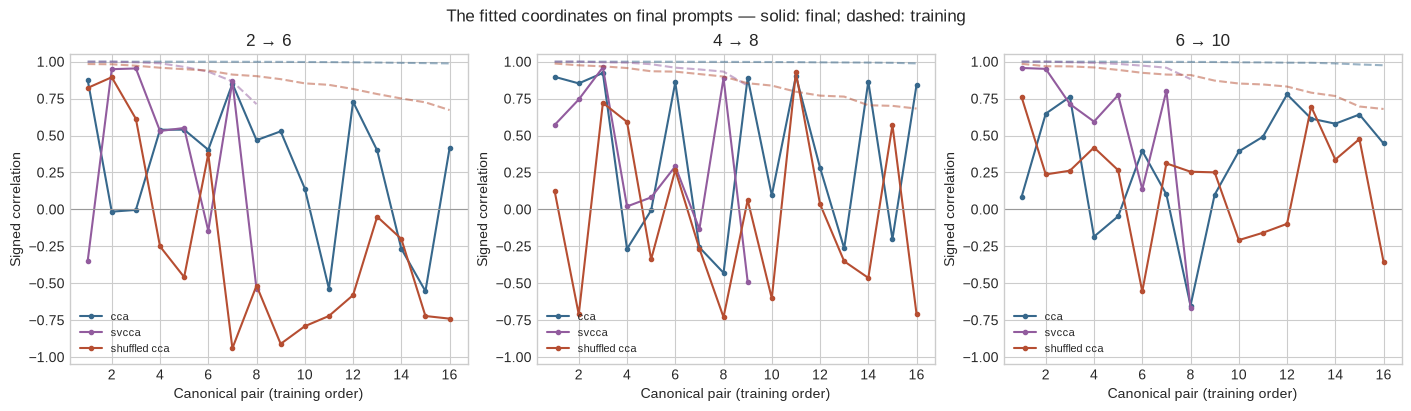

In [15]:
colors = {
    "cca": "#37688c",
    "svcca": "#925c9e",
    "procrustes": "#cd8738",
    "shuffled_cca": "#b64e32",
    "ridge": "#438579",
}
fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
for ax, (key, pair) in zip(axes, results["pairs"].items()):
    for method in ["cca", "svcca", "shuffled_cca"]:
        row = next(r for r in pair["final"] if r["name"] == method + "_rank16")
        x = range(1, row["effective_rank"] + 1)
        ax.plot(x, row["training_correlations"], "--", alpha=0.5, color=colors[method])
        ax.plot(
            x,
            row["final_correlations"],
            "o-",
            markersize=3,
            color=colors[method],
            label=method.replace("_", " "),
        )
    ax.axhline(0, color="#999", linewidth=0.8)
    ax.set(
        title=key.replace("_to_", " → "),
        xlabel="Canonical pair (training order)",
        ylabel="Signed correlation",
        ylim=(-1.05, 1.05),
    )
    ax.legend(fontsize=8)
fig.suptitle("The fitted coordinates on final prompts — solid: final; dashed: training")
fig.savefig(assets_dir / "alignment_real_correlations.png", dpi=160)
plt.show()


<details><summary>Interpreting the actual spectra</summary>

Training correlations are close to one, but final correlations vary substantially
and some reverse sign. These are fixed directions, so those failures remain
visible. SVCCA's 99% cutoff leaves only 8, 9 and 8 canonical pairs for the three
layer comparisons; requesting rank 16 does not create missing directions.

Nearly equal canonical correlations can also make individual axes poorly
identified: an aligned subspace may admit many rotated bases. A drop in one
fixed pair's correlation is not proof that all shared information disappeared.
The intervention curves ask a separate, behavioral question about the particular
map we fitted.

</details>

## Signature result — can the alignment transport the donor's change?

Each curve now measures an actual intervention, not a correlation. Lower
`KL(native donor || transported)` is better. The unchanged/no-op reference
shows how much there was to reproduce at each target layer. Each gray point is
a complete random-direction draw averaged over the same 96 prompts, not a
confidence interval. The green ridge line is a predictive baseline.

Do not compare tiny absolute KL at an early layer with a harder later-layer
intervention without looking at the unchanged reference. A near-zero baseline
means the donor changed very little to begin with.


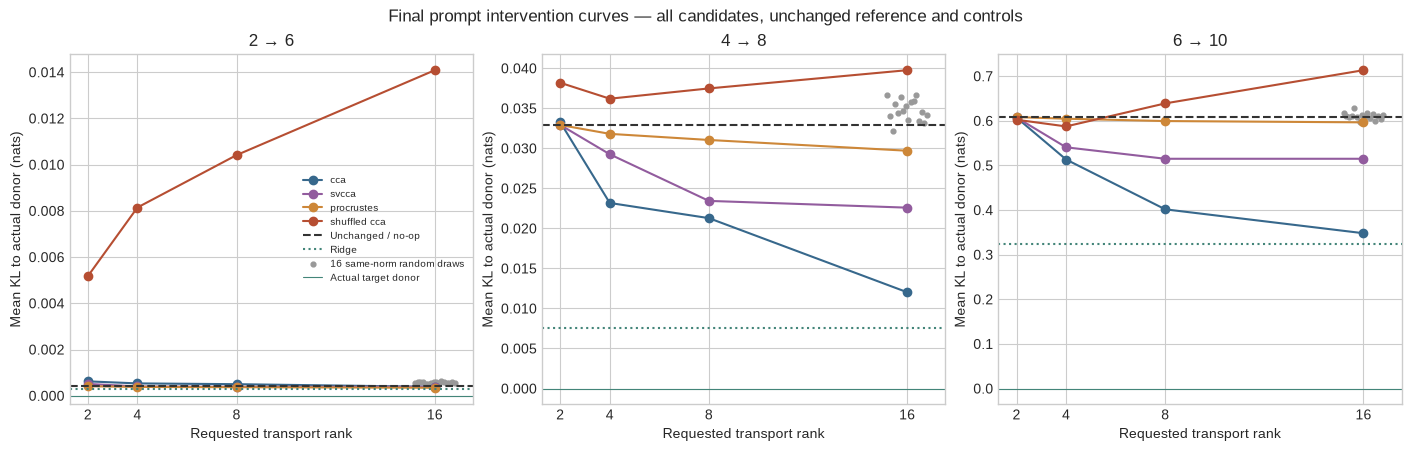

In [16]:
def final_outcomes(key, condition, seen=None, draw=None):
    pair = results["pairs"][key]
    return [
        r
        for r in results["outcomes"]
        if r["split"] == "final"
        and r["source_layer"] == pair["source_layer"]
        and r["target_layer"] == pair["target_layer"]
        and r["condition"] == condition
        and (seen is None or r["seen_names"] == seen)
        and (draw is None or r["draw"] == draw)
    ]


def outcome_mean(key, condition, field, seen=None, draw=None):
    rows = final_outcomes(key, condition, seen, draw)
    assert rows, "This comparison has no measured rows."
    return float(np.mean([r[field] for r in rows]))


fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), constrained_layout=True)
for ax, (key, pair) in zip(axes, results["pairs"].items()):
    for method in ["cca", "svcca", "procrustes", "shuffled_cca"]:
        candidates = [r for r in pair["final"] if r["method"] == method]
        ax.plot(
            [r["requested_rank"] for r in candidates],
            [r["mean_kl"] for r in candidates],
            "o-",
            color=colors[method],
            label=method.replace("_", " "),
        )
    baseline = outcome_mean(key, "baseline", "kl_to_native_donor")
    ridge = outcome_mean(key, "ridge_0.1", "kl_to_native_donor")
    ax.axhline(baseline, color="#333", linestyle="--", label="Unchanged / no-op")
    ax.axhline(ridge, color=colors["ridge"], linestyle=":", label="Ridge")
    random_values = [
        outcome_mean(key, "same_norm_random", "kl_to_native_donor", draw=d)
        for d in range(protocol["null_draws"])
    ]
    ax.scatter(
        np.linspace(15.2, 16.8, len(random_values)),
        random_values,
        s=12,
        color="#999",
        label="16 same-norm random draws",
    )
    ax.axhline(0, color="#438579", linewidth=0.8, label="Actual target donor")
    ax.set(
        title=key.replace("_to_", " → "),
        xlabel="Requested transport rank",
        ylabel="Mean KL to actual donor (nats)",
        xticks=protocol["canonical_ranks"],
    )
axes[0].legend(fontsize=7)
fig.suptitle("Final prompt intervention curves — all candidates, unchanged reference and controls")
fig.savefig(assets_dir / "alignment_real_transport_curves.png", dpi=160)
plt.show()


### Exercise 6 — Separate similarity, reproduction and correctness

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> You should spend 10 minutes on this exercise.
> ```

For each layer pair, compare the correlation and KL figures. Write three
sentences: one about coordinate agreement, one about reproducing the local
donor intervention, and one about which name the model actually predicts.
What evidence is missing from the first two figures for that third sentence?

<details><summary>Help — a metric is tied to a specific question</summary>

A representation can align while downstream computations respond differently.
KL compares two distributions, even if both give the wrong answer. You need
actual top tokens or probabilities to say whether the desired name was recovered.

</details>

<details><summary>Solution</summary>

A high final correlation supports shared linear information on these paired
prompts. A small KL relative to the unchanged reference supports reproduction of
the measured donor intervention. Neither implies correct name prediction: check
the name plot and token gallery. If the unchanged reference is already tiny,
small absolute KL alone is weak evidence of successful transport.

</details>

## Which names does GPT-2 actually say?

The next plot uses the **whole vocabulary** winner. A success is the changed
recipient's name, never an argmax restricted to the two names. The original
prompt's correct recipient rate is printed beside each panel so that donor
success is interpreted against actual baseline task ability. All final prompts
count, including the 30 rows containing new names.


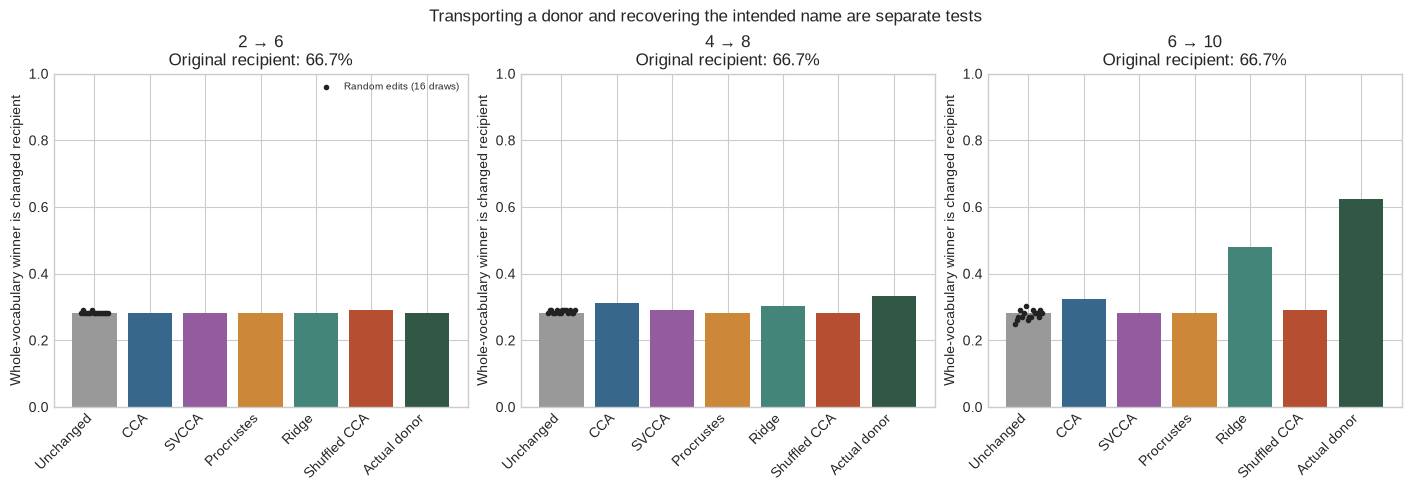

In [17]:
conditions = [
    "baseline",
    "cca_rank16",
    "svcca_rank16",
    "procrustes_rank16",
    "ridge_0.1",
    "shuffled_cca_rank16",
    "native_donor",
]
labels = ["Unchanged", "CCA", "SVCCA", "Procrustes", "Ridge", "Shuffled CCA", "Actual donor"]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), constrained_layout=True)
for ax, key in zip(axes, results["pairs"]):
    values = [outcome_mean(key, c, "changed_recipient_top") for c in conditions]
    ax.bar(
        range(len(values)),
        values,
        color=[
            "#999",
            colors["cca"],
            colors["svcca"],
            colors["procrustes"],
            colors["ridge"],
            colors["shuffled_cca"],
            "#315845",
        ],
    )
    random_values = [
        outcome_mean(key, "same_norm_random", "changed_recipient_top", draw=d)
        for d in range(protocol["null_draws"])
    ]
    ax.scatter(
        np.linspace(-0.25, 0.25, len(random_values)),
        random_values,
        s=9,
        color="#222",
        label="Random edits (16 draws)",
    )
    original = outcome_mean(key, "baseline", "original_recipient_top")
    ax.set(
        title=key.replace("_to_", " → ") + f"\nOriginal recipient: {original:.1%}",
        ylabel="Whole-vocabulary winner is changed recipient",
        ylim=(0, 1),
    )
    ax.set_xticks(range(len(values)), labels, rotation=45, ha="right")
axes[0].legend(fontsize=7)
fig.suptitle("Transporting a donor and recovering the intended name are separate tests")
fig.savefig(assets_dir / "alignment_real_name_changes.png", dpi=160)
plt.show()


## A fixed gallery, including failures

These are predetermined row indices from the first final template: four early
rows and four near the seen/unseen-name boundary. They are not selected for
success. The cell prints both prompts. The heatmap shows the actual winning
next token under each condition; green marks agreement with the measured native
donor's winning token, even when that token is itself an incorrect name.


00 recipient: After Mary and John went to the cafe, John gave a cup to
   donor:     After John and Mary went to the cafe, Mary gave a cup to
01 recipient: After John and Mary went to the cafe, Mary gave a cup to
   donor:     After Mary and John went to the cafe, John gave a cup to
02 recipient: After John and Tom went to the cafe, Tom gave a cup to
   donor:     After Tom and John went to the cafe, John gave a cup to
03 recipient: After Tom and John went to the cafe, John gave a cup to
   donor:     After John and Tom went to the cafe, Tom gave a cup to
22 recipient: After Alice and Anne went to the cafe, Anne gave a cup to
   donor:     After Anne and Alice went to the cafe, Alice gave a cup to
23 recipient: After Anne and Alice went to the cafe, Alice gave a cup to
   donor:     After Alice and Anne went to the cafe, Anne gave a cup to
24 recipient: After Anne and Paul went to the cafe, Paul gave a cup to
   donor:     After Paul and Anne went to the cafe, Anne gave a cup to
25 rec

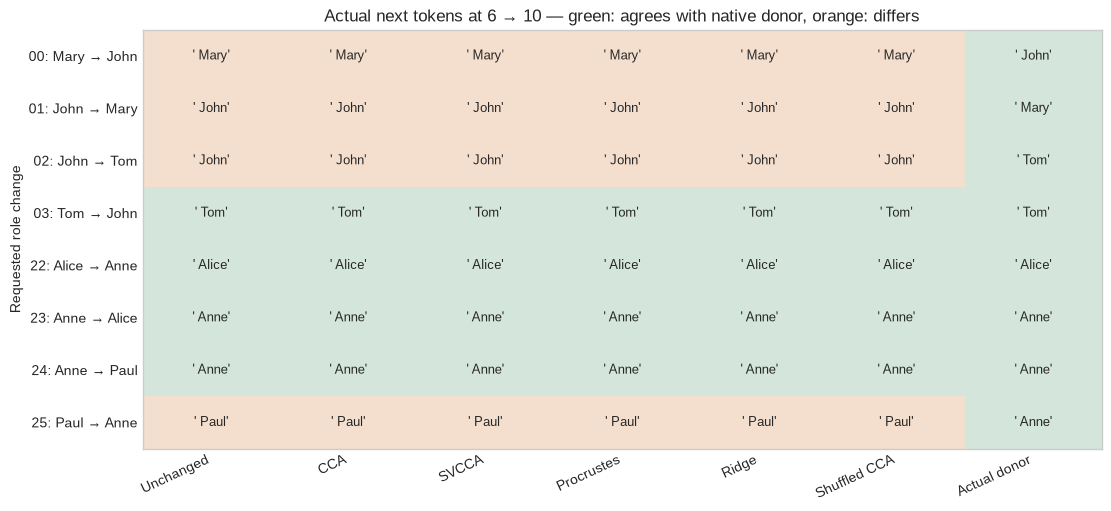

In [18]:
gallery_indices = [0, 1, 2, 3, 22, 23, 24, 25]
key = "6_to_10"
gallery_rows = results["rows"]["final"]
gallery_donors = donor_indices(gallery_rows)
for i in gallery_indices:
    print(f"{i:02d} recipient: {gallery_rows[i]['prompt']}")
    print(f"   donor:     {gallery_rows[gallery_donors[i]]['prompt']}")
measured = actual["logits"][key]
token_matrix = t.stack([measured[c][gallery_indices].argmax(-1) for c in conditions], 1)
agreement = token_matrix.eq(measured["native_donor"][gallery_indices].argmax(-1)[:, None])
fig, ax = plt.subplots(figsize=(11, 5), constrained_layout=True)
ax.grid(False)
ax.imshow(
    agreement.numpy(),
    vmin=0,
    vmax=1,
    cmap=plt.matplotlib.colors.ListedColormap(["#f4dfce", "#d4e5dc"]),
    aspect="auto",
)
for row in range(len(gallery_indices)):
    for column in range(len(conditions)):
        ax.text(
            column,
            row,
            repr(tokenizer.decode(int(token_matrix[row, column]))),
            ha="center",
            va="center",
            fontsize=9,
        )
ax.set_xticks(range(len(labels)), labels, rotation=25, ha="right")
ax.set_yticks(
    range(len(gallery_indices)),
    [
        f"{i:02d}: {gallery_rows[i]['recipient']} → {gallery_rows[i]['subject']}"
        for i in gallery_indices
    ],
)
ax.set(
    title="Actual next tokens at 6 → 10 — green: agrees with native donor, orange: differs",
    ylabel="Requested role change",
)
fig.savefig(assets_dir / "alignment_real_token_gallery.png", dpi=160)
plt.show()


## Does a change in names expose a weak map?

The final templates are new for both groups below. Only the right panel also
contains names absent from training. This isolates one additional distribution
change, although the groups are small and share templates/name pairs. Each gray
dot is one matched random draw averaged inside that group. Treat the difference
as a descriptive comparison, not a confidence interval or a causal estimate of
"unseen name difficulty."


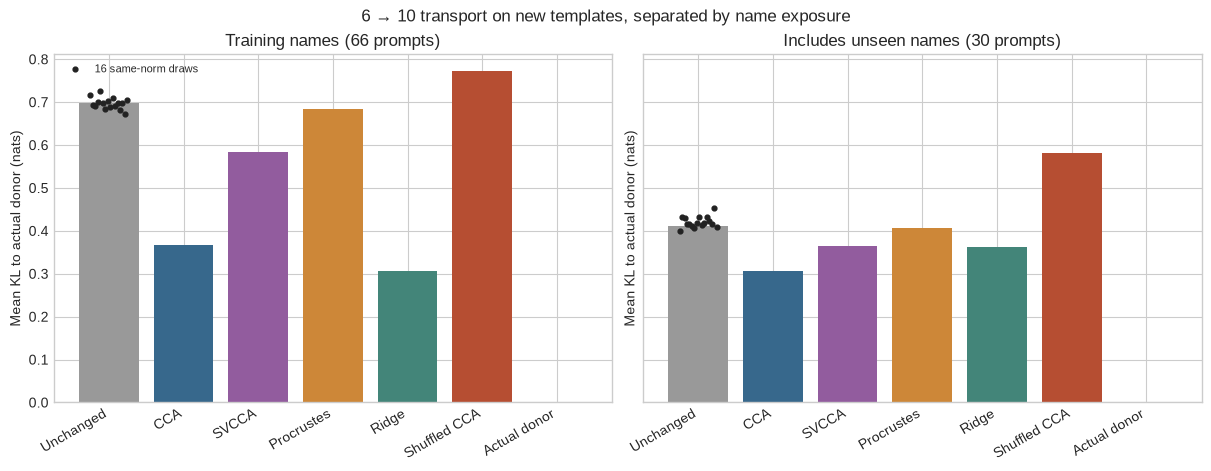

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), constrained_layout=True, sharey=True)
key = "6_to_10"
for ax, seen in zip(axes, [True, False]):
    values = [outcome_mean(key, c, "kl_to_native_donor", seen=seen) for c in conditions]
    ax.bar(
        range(len(values)),
        values,
        color=[
            "#999",
            colors["cca"],
            colors["svcca"],
            colors["procrustes"],
            colors["ridge"],
            colors["shuffled_cca"],
            "#315845",
        ],
    )
    random_values = [
        outcome_mean(key, "same_norm_random", "kl_to_native_donor", seen=seen, draw=d)
        for d in range(protocol["null_draws"])
    ]
    ax.scatter(
        np.linspace(-0.25, 0.25, len(random_values)),
        random_values,
        s=12,
        color="#222",
        label="16 same-norm draws",
    )
    count = len(final_outcomes(key, "baseline", seen=seen))
    ax.set(
        title=("Training names" if seen else "Includes unseen names") + f" ({count} prompts)",
        ylabel="Mean KL to actual donor (nats)",
    )
    ax.set_xticks(range(len(labels)), labels, rotation=30, ha="right")
axes[0].legend(fontsize=8)
fig.suptitle("6 → 10 transport on new templates, separated by name exposure")
fig.savefig(assets_dir / "alignment_real_name_generalization.png", dpi=160)
plt.show()


## Try It Yourself — turn the transport rank and inspect a real distribution

Choose a final row, a layer pair and a rank (zero is allowed). This cell performs
new native model interventions using the training fit; it does not load a plot
or a report. The displayed vocabulary is the union of each condition's top four
tokens plus both names. The probabilities are still from the full vocabulary,
so the displayed bars need not sum to one. The horizontal line is only a
visual aid at zero.

Try a row with an unseen name, then set rank to zero. Predict which curve should
be identical to unchanged output. Increase the rank again; check whether a more
correlated representation actually shifts probability toward the native donor.
Every run includes a random edit with the same norm as your proposed edit.


Recipient: After Mary and John went to the cafe, John gave a cup to
Donor:     After John and Mary went to the cafe, Mary gave a cup to


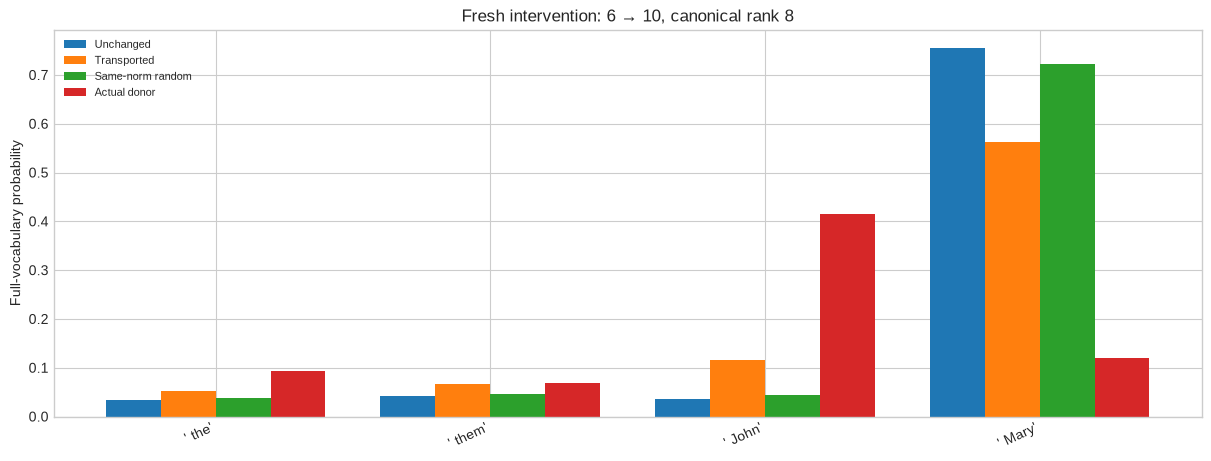

In [20]:
play_row = 0
play_pair = "6_to_10"
play_rank = 8
pair = results["pairs"][play_pair]
row = results["rows"]["final"][play_row]
donor_index = donor_indices(results["rows"]["final"])[play_row]
donor_row = results["rows"]["final"][donor_index]
# A fresh two-prompt forward pass keeps this play independent of stored logits.
play_capture = capture_rows(model, tokenizer, [row, donor_row], position_mode="prediction")
x = play_capture["activations"][:, pair["source_layer"]].double()
y = play_capture["activations"][:, pair["target_layer"]].double()
fit = next(c["fit"] for c in actual["fits"][play_pair] if c["name"] == "cca_rank16")
difference = cca_difference_transport(x[1:2] - x[0:1], fit, play_rank)
generator = t.Generator().manual_seed(987)
random_direction = t.randn(difference.shape, generator=generator, dtype=difference.dtype)
random_difference = random_direction / random_direction.norm() * difference.norm()
play_logits = {"Unchanged": play_capture["logits"][0:1]}
for label, replacement in [
    ("Transported", y[0:1] + difference),
    ("Same-norm random", y[0:1] + random_difference),
    ("Actual donor", y[1:2]),
]:
    play_logits[label] = replace_rows(
        model, tokenizer, [row], pair["target_layer"], replacement, position_mode="prediction"
    )
print("Recipient:", row["prompt"])
print("Donor:    ", donor_row["prompt"])
name_tokens = [
    tokenizer.encode(" " + name, add_special_tokens=False)[0]
    for name in [row["recipient"], row["subject"]]
]
selected_tokens = sorted(
    set(
        name_tokens + [int(i) for logits in play_logits.values() for i in logits[0].topk(4).indices]
    )
)
fig, ax = plt.subplots(figsize=(12, 4.5), constrained_layout=True)
for i, (label, logits) in enumerate(play_logits.items()):
    values = logits[0].softmax(-1)[selected_tokens].tolist()
    ax.bar(np.arange(len(selected_tokens)) + (i - 1.5) * 0.2, values, width=0.2, label=label)
ax.axhline(0, color="#999", linewidth=0.7)
ax.set_xticks(
    range(len(selected_tokens)),
    [repr(tokenizer.decode(i)) for i in selected_tokens],
    rotation=25,
    ha="right",
)
ax.set(
    ylabel="Full-vocabulary probability",
    title=f"Fresh intervention: {play_pair.replace('_to_', ' → ')}, canonical rank {play_rank}",
)
ax.legend(fontsize=8)
fig.savefig(assets_dir / "alignment_real_play.png", dpi=160)
plt.show()
# Retain the actual play probabilities and parameters alongside the visible result.
t.save(
    {
        "row": row,
        "donor": donor_row,
        "pair": play_pair,
        "rank": play_rank,
        "activations": play_capture,
        "logits": play_logits,
        "difference": difference,
        "random_difference": random_difference,
    },
    study_directory / "actual_play.pt",
)


## Interpreting the result

In the recorded run, the 6→10 unchanged reference has about 0.61 nats of KL to
the actual donor. Rank-16 CCA lowers this to 0.35, ridge to 0.32, while shuffled
CCA reaches 0.71. This is partial reproduction, not interchangeable behavior.
CCA agrees with the donor's winning token on 46/96 prompts; ridge on 62/96.
The desired changed name wins on 31/96 CCA prompts, 46/96 ridge prompts and
60/96 native-donor prompts. Even the native donor is not an all-correct oracle.

In the first gallery row, the actual donor changes “Mary” to “John”; every
fitted map shown still predicts “Mary.” The play cell shows the intermediate
probability shift rather than hiding it behind the unchanged top token. In the
Tom→John row the native donor itself keeps “Tom,” so its green agreement cells
are not evidence of successful role reversal. Both kinds of failure matter.

Return to the question at the start: common coordinates make some comparisons
possible, but they do not certify interchangeable computations. Distinguish
three observations in your own words: held-out coordinate correlation, KL
reproduction of an actual local donor, and the model's winning name. Use one
failed row from the fixed gallery to explain why those answers can disagree.

<details><summary>Help — a useful negative result</summary>

If CCA has strong held-out correlations and fails the token change, the numerical
CCA test has not necessarily failed. Its objective is paired linear correlation.
Our separate canonical regression map and its truncation need not preserve the
directions that downstream computation uses. Compare ridge, same-rank Procrustes,
shuffled correspondence and the full donor before deciding what failed.

</details>

## Limitations

This is a cross-layer study in one GPT-2 checkpoint on small, structured IOI
prompt families. It does not establish alignment across independently trained
models, recover the IOI circuit, or show that CCA directions are individual
causal features. The recipient's other positions remain unchanged during a
patch. Even a full target donor can disagree with the donor prompt's answer.

PCA and SVCCA cutoffs are modeling choices. Full CCA is invariant to invertible
changes of feature coordinates when the retained spaces are unchanged; a
variance cutoff or explicit PCA rank cap can break that invariance. Procrustes
restricts its coordinate transform to preserve lengths. Canonical regression
is one explicit way to turn alignment into a prediction rule, not a consequence
that CCA itself guarantees.

The Pythia-70M development attempt on antonym prompts mostly retained generic
next tokens under donor patches. That is a retained negative example of a weak
behavioral setup. This GPT-2 study makes the local donor effect easier to
inspect; neither study is a full reproduction of the representation-similarity
papers.

## Further investigations

Before running a new experiment, state which failure you expect. For example,
use the synthetic low-variance task to find the exact cutoff where the output
change disappears; separate sign instability from actual loss of held-out
correlation; or compare two real rows with similar coordinate scores but
different donor effects. Keep a fresh evaluation set if your exploration starts
choosing ranks, names or layers to improve the final result.

## Reading

- [Raghu et al., SVCCA](https://arxiv.org/abs/1706.05806v2) and [the authors' code](https://github.com/google/svcca): variance reduction followed by canonical comparison.
- [Kornblith et al., Similarity of Neural Network Representations Revisited](https://arxiv.org/abs/1905.00414v4): the sample-dimension failure of invertible-transform-invariant similarity measures.
- [Wang et al., Interpretability in the Wild](https://arxiv.org/abs/2211.00593): GPT-2's indirect-object task and causal circuit analysis. Our exercise borrows the task structure and studies a different question.
